In [ ]:
!pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 49.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 76.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]


In [ ]:
import sys, os, json, hashlib, platform, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

# ---------- paths ----------
IN_COLAB = "google.colab" in sys.modules

# Project folder on Drive (outputs go here). Change if you like; it is created if missing.
DRIVE_PROJECT = Path("/content/drive/MyDrive/german-credit-risk")

# Find german.data: expected location first, otherwise search My Drive
DATA_PATH = DRIVE_PROJECT / "data" / "raw" / "german.data"
if not DATA_PATH.exists():
    hits = [p for p in Path("/content/drive/MyDrive").rglob("german.data") if p.is_file()]
    assert hits, "german.data not found in My Drive. Check the upload location."
    DATA_PATH = hits[0]
print("data file:", DATA_PATH)

ARTIFACT_DIR = DRIVE_PROJECT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# MLflow store lives on the fast local Colab disk (SQLite on Drive can be slow/locky)
MLFLOW_DIR = Path("/content/mlflow_work")
MLFLOW_DIR.mkdir(exist_ok=True)
os.chdir(MLFLOW_DIR)

# ---------- config ----------
CFG = {
    "seed": 42,
    "test_size": 0.2,
    "cv_folds": 5,
    "cost_fn": 5,   # actual defaulter approved as good
    "cost_fp": 1,   # good applicant rejected
}
SEED = CFG["seed"]

mlflow.set_tracking_uri(f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').as_posix()}")
mlflow.set_experiment("german-credit-default-risk")
print("sklearn:", sklearn.__version__, "| artifacts ->", ARTIFACT_DIR)

data file: /content/drive/MyDrive/german-credit-risk/german.data


2026/11/07 12:05:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/07 12:05:17 INFO mlflow.store.db.utils: Updating database tables
2026/11/07 12:05:21 INFO mlflow.tracking.fluent: Experiment with name 'german-credit-default-risk' does not exist. Creating a new experiment.


sklearn: 1.6.1 | artifacts -> /content/drive/MyDrive/german-credit-risk/artifacts


In [ ]:
COLUMNS = ["status_checking", "duration_months", "credit_history", "purpose", "credit_amount",
           "savings", "employment_since", "installment_rate", "personal_status_sex",
           "other_debtors", "residence_since", "property", "age", "other_installment_plans",
           "housing", "existing_credits", "job", "num_dependents", "telephone",
           "foreign_worker", "class_raw"]

NUM_COLS = ["duration_months", "credit_amount", "installment_rate", "residence_since",
            "age", "existing_credits", "num_dependents"]
CAT_COLS = ["status_checking", "credit_history", "purpose", "savings", "employment_since",
            "personal_status_sex", "other_debtors", "property", "other_installment_plans",
            "housing", "job", "telephone", "foreign_worker"]
SENSITIVE = ["personal_status_sex", "foreign_worker"]

LABELS = {
 "status_checking": {"A11": "< 0 DM", "A12": "0 to < 200 DM", "A13": ">= 200 DM / salary assigned", "A14": "no checking account"},
 "credit_history": {"A30": "no credits taken / all paid duly", "A31": "all credits at this bank paid duly",
                    "A32": "existing credits paid duly till now", "A33": "delay in paying off in the past",
                    "A34": "critical account / other credits elsewhere"},
 "purpose": {"A40": "car (new)", "A41": "car (used)", "A42": "furniture/equipment", "A43": "radio/television",
             "A44": "domestic appliances", "A45": "repairs", "A46": "education", "A47": "vacation",
             "A48": "retraining", "A49": "business", "A410": "others"},
 "savings": {"A61": "< 100 DM", "A62": "100 to < 500 DM", "A63": "500 to < 1000 DM", "A64": ">= 1000 DM", "A65": "unknown / no savings"},
 "employment_since": {"A71": "unemployed", "A72": "< 1 year", "A73": "1 to < 4 years", "A74": "4 to < 7 years", "A75": ">= 7 years"},
 "personal_status_sex": {"A91": "male: divorced/separated", "A92": "female: divorced/separated/married",
                         "A93": "male: single", "A94": "male: married/widowed", "A95": "female: single"},
 "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
 "property": {"A121": "real estate", "A122": "savings agreement / life insurance", "A123": "car or other", "A124": "unknown / no property"},
 "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
 "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
 "job": {"A171": "unemployed / unskilled non-resident", "A172": "unskilled resident",
         "A173": "skilled employee / official", "A174": "management / self-employed / highly qualified"},
 "telephone": {"A191": "none", "A192": "yes (registered)"},
 "foreign_worker": {"A201": "yes", "A202": "no"},
}
assert set(LABELS) == set(CAT_COLS)

In [ ]:
df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=COLUMNS)
assert df.shape == (1000, 21), df.shape

df["default"] = (df["class_raw"] == 2).astype(int)   # 1 = bad / default

# provenance
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
data_manifest = {"file": DATA_PATH.name, "sha256": sha256, "rows": int(df.shape[0]),
                 "source": "UCI Statlog (German Credit Data), Prof. Hans Hofmann, Univ. Hamburg"}
print(data_manifest)
df.head()

{'file': 'german.data', 'sha256': 'b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871', 'rows': 1000, 'source': 'UCI Statlog (German Credit Data), Prof. Hans Hofmann, Univ. Hamburg'}


,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,class_raw,default
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,67,A143,A152,2,A173,1,A192,A201,1,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,22,A143,A152,1,A173,1,A191,A201,2,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,49,A143,A152,1,A172,2,A191,A201,1,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,45,A143,A153,1,A173,2,A191,A201,1,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,53,A143,A153,2,A173,2,A191,A201,2,1


missing values: 0
duplicate rows: 0

Class balance (1 = default):
default
0    700
1    300
Name: count, dtype: int64 
 default
0    0.7
1    0.3
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


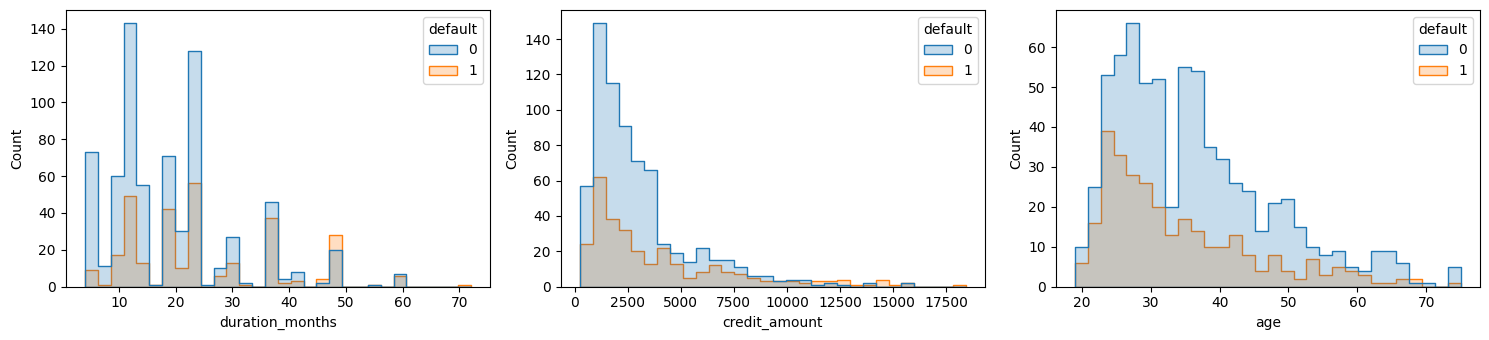

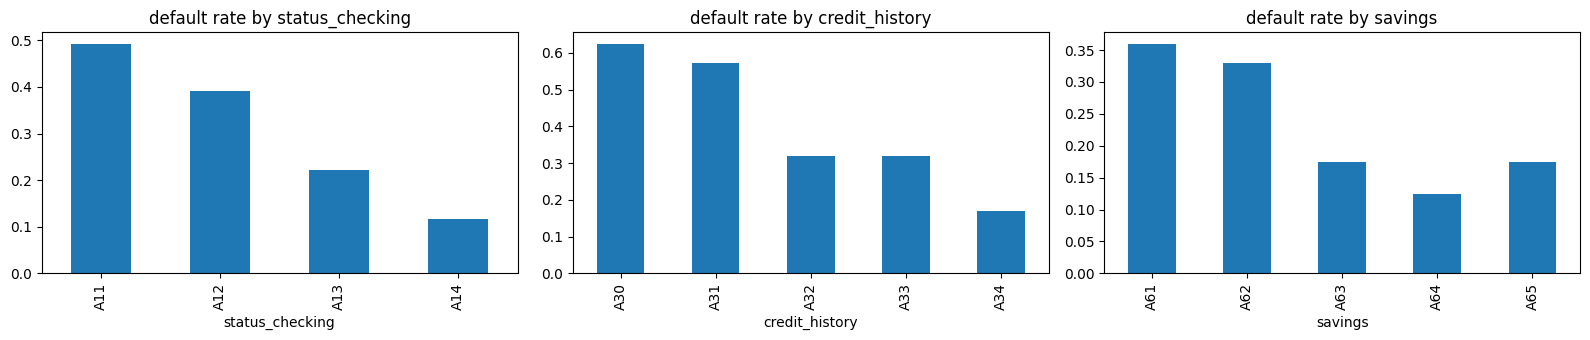

In [ ]:
print("missing values:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))

# every categorical code must be a documented one
for c in CAT_COLS:
    bad = set(df[c].unique()) - set(LABELS[c])
    assert not bad, (c, bad)

print("\nClass balance (1 = default):")
print(df["default"].value_counts(), "\n", df["default"].value_counts(normalize=True).round(3))
display(df[NUM_COLS].describe().T)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, c in zip(ax, ["duration_months", "credit_amount", "age"]):
    sns.histplot(data=df, x=c, hue="default", bins=30, ax=a, element="step")
plt.tight_layout(); plt.show()

# default rate by a few categorical features
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for a, c in zip(ax, ["status_checking", "credit_history", "savings"]):
    df.groupby(c)["default"].mean().sort_index().plot.bar(ax=a, title=f"default rate by {c}")
plt.tight_layout(); plt.show()

In [ ]:
FEATURES = NUM_COLS + CAT_COLS
X = df[FEATURES]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CFG["test_size"], stratify=y, random_state=SEED)

print(X_train.shape, X_test.shape)
print("default rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
split_info = {"train_idx": X_train.index.tolist(), "test_idx": X_test.index.tolist()}
assert not set(split_info["train_idx"]) & set(split_info["test_idx"])

(800, 20) (200, 20)
default rate train/test: 0.3 0.3


In [ ]:
def build_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ], remainder="drop")

def model_specs():
    return {
        "decision_tree": (DecisionTreeClassifier(random_state=SEED), {
            "clf__max_depth": [3, 4, 5, 6, 8],
            "clf__min_samples_leaf": [5, 10, 20],
            "clf__class_weight": [None, "balanced"]}),
        "logistic_regression": (LogisticRegression(max_iter=3000), {
            "clf__C": [0.01, 0.1, 1, 10],
            "clf__class_weight": [None, "balanced"]}),
        "random_forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1), {
            "clf__n_estimators": [200, 400],
            "clf__max_depth": [None, 6, 10],
            "clf__min_samples_leaf": [1, 3, 5],
            "clf__class_weight": [None, "balanced_subsample"]}),
    }

def expected_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (CFG["cost_fn"] * fn + CFG["cost_fp"] * fp) / len(y_true)

def best_threshold(y_true, proba):
    grid = np.linspace(0.05, 0.95, 91)
    costs = [expected_cost(y_true, (proba >= t).astype(int)) for t in grid]
    i = int(np.argmin(costs))
    return float(grid[i]), float(costs[i])

def evaluate(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": float(thr),
            "precision": float(precision_score(y_true, pred, zero_division=0)),
            "recall": float(recall_score(y_true, pred, zero_division=0)),
            "f1": float(f1_score(y_true, pred, zero_division=0)),
            "roc_auc": float(roc_auc_score(y_true, proba)),
            "pr_auc": float(average_precision_score(y_true, proba)),
            "expected_cost": float(expected_cost(y_true, pred)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

In [ ]:
def run_experiment(fs_name, num_cols, cat_cols):
    cv = StratifiedKFold(n_splits=CFG["cv_folds"], shuffle=True, random_state=SEED)
    results = {}
    for name, (est, grid) in model_specs().items():
        pipe = Pipeline([("prep", build_preprocessor(num_cols, cat_cols)), ("clf", est)])
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
        gs.fit(X_train, y_train)
        best = gs.best_estimator_

        # threshold chosen ONLY from out-of-fold predictions on the training set
        oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        thr, oof_cost = best_threshold(y_train, oof)

        proba_test = best.predict_proba(X_test)[:, 1]
        m_default = evaluate(y_test, proba_test, 0.5)
        m_tuned = evaluate(y_test, proba_test, thr)

        with mlflow.start_run(run_name=f"{fs_name}-{name}"):
            mlflow.log_params({"feature_set": fs_name, "model": name, "seed": SEED,
                               "test_size": CFG["test_size"], "data_sha256": sha256[:16],
                               **gs.best_params_})
            mlflow.log_metrics({"cv_roc_auc": float(gs.best_score_), "oof_cost": oof_cost,
                                **{f"test_{k}": v for k, v in m_tuned.items()},
                                **{f"test05_{k}": v for k, v in m_default.items()}})

        results[name] = {"model": best, "params": gs.best_params_, "cv_auc": float(gs.best_score_),
                         "threshold": thr, "oof_cost": oof_cost, "test_default": m_default,
                         "test_tuned": m_tuned, "proba_test": proba_test,
                         "num_cols": num_cols, "cat_cols": cat_cols}
        print(f"[{fs_name}] {name}: cv_auc={gs.best_score_:.3f} thr={thr:.2f} "
              f"test_auc={m_tuned['roc_auc']:.3f}")
    return results

In [ ]:
FEATURE_SETS = {
    "all_features": (NUM_COLS, CAT_COLS),
    "no_sensitive": (NUM_COLS, [c for c in CAT_COLS if c not in SENSITIVE]),
}
all_results = {fs: run_experiment(fs, *cols) for fs, cols in FEATURE_SETS.items()}

[all_features] decision_tree: cv_auc=0.720 thr=0.07 test_auc=0.663
[all_features] logistic_regression: cv_auc=0.784 thr=0.18 test_auc=0.810
[all_features] random_forest: cv_auc=0.800 thr=0.36 test_auc=0.800
[no_sensitive] decision_tree: cv_auc=0.724 thr=0.07 test_auc=0.693
[no_sensitive] logistic_regression: cv_auc=0.775 thr=0.18 test_auc=0.809
[no_sensitive] random_forest: cv_auc=0.795 thr=0.23 test_auc=0.807


In [ ]:
rows = []
for fs, res in all_results.items():
    for name, r in res.items():
        t = r["test_tuned"]
        rows.append({"feature_set": fs, "model": name, "cv_auc": r["cv_auc"], "oof_cost": r["oof_cost"],
                     "threshold": r["threshold"], "test_auc": t["roc_auc"], "test_pr_auc": t["pr_auc"],
                     "precision": t["precision"], "recall": t["recall"], "f1": t["f1"],
                     "test_cost": t["expected_cost"], "test_cost@0.5": r["test_default"]["expected_cost"]})
comparison = pd.DataFrame(rows).round(3)
comparison

,feature_set,model,cv_auc,oof_cost,threshold,test_auc,test_pr_auc,precision,recall,f1,test_cost,test_cost@0.5
0,all_features,decision_tree,0.720,0.589,0.07,0.663,0.506,0.369,0.867,0.517,0.645,0.965
1,all_features,logistic_regression,0.784,0.512,0.18,0.810,0.664,0.424,0.883,0.573,0.535,0.810
2,all_features,random_forest,0.800,0.509,0.36,0.800,0.643,0.445,0.883,0.592,0.505,0.685
3,no_sensitive,decision_tree,0.724,0.601,0.07,0.693,0.459,0.363,0.950,0.525,0.575,1.030
4,no_sensitive,logistic_regression,0.775,0.521,0.18,0.809,0.660,0.382,0.867,0.531,0.620,0.930
5,no_sensitive,random_forest,0.795,0.516,0.23,0.808,0.679,0.426,0.867,0.571,0.550,0.900


In [ ]:
FINAL_FS = "no_sensitive"   # policy choice: do not use sex or foreign-worker status as inputs
final_name = min(all_results[FINAL_FS], key=lambda k: all_results[FINAL_FS][k]["oof_cost"])
final = all_results[FINAL_FS][final_name]
final_model, thr = final["model"], final["threshold"]
used_cols = final["num_cols"] + final["cat_cols"]
print("Final:", final_name, "| threshold:", round(thr, 2))
print(json.dumps(final["test_tuned"], indent=2))

Final: random_forest | threshold: 0.23
{
  "threshold": 0.22999999999999998,
  "precision": 0.4262295081967213,
  "recall": 0.8666666666666667,
  "f1": 0.5714285714285714,
  "roc_auc": 0.8075,
  "pr_auc": 0.678982013851808,
  "expected_cost": 0.55,
  "tn": 70,
  "fp": 70,
  "fn": 8,
  "tp": 52
}


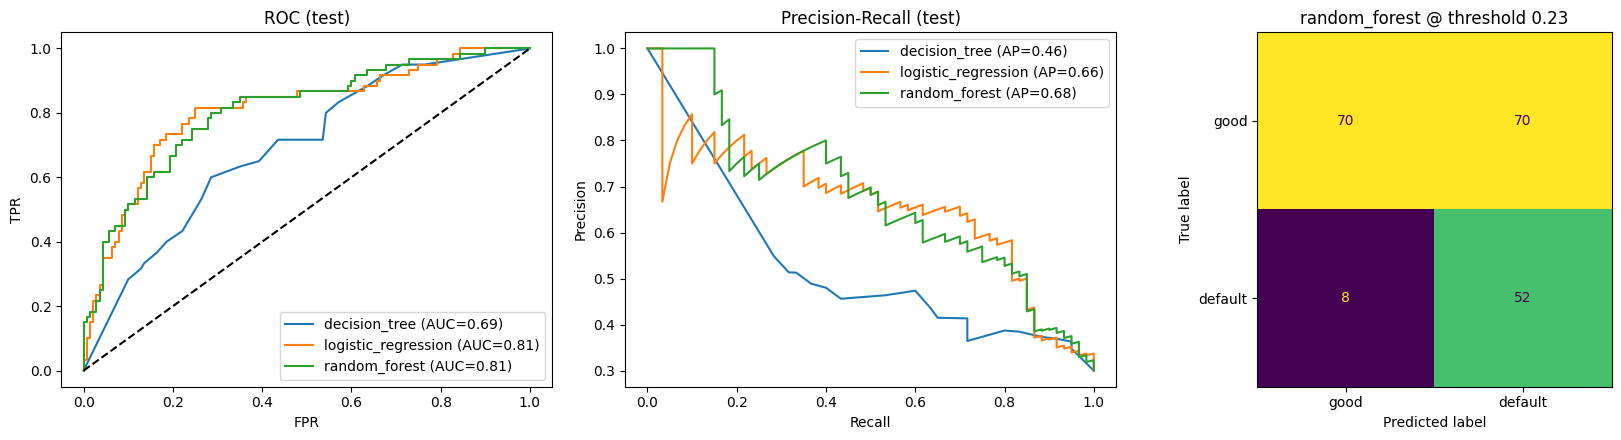

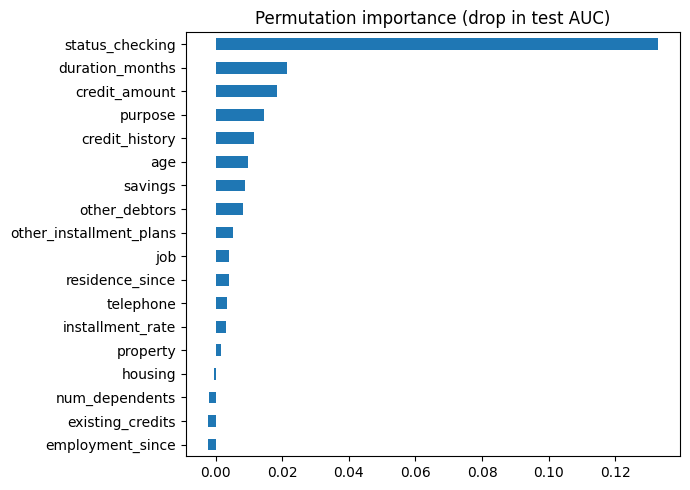

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, r in all_results[FINAL_FS].items():
    fpr, tpr, _ = roc_curve(y_test, r["proba_test"])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={r['test_tuned']['roc_auc']:.2f})")
    p, rc, _ = precision_recall_curve(y_test, r["proba_test"])
    ax[1].plot(rc, p, label=f"{name} (AP={r['test_tuned']['pr_auc']:.2f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC (test)", xlabel="FPR", ylabel="TPR"); ax[0].legend()
ax[1].set(title="Precision-Recall (test)", xlabel="Recall", ylabel="Precision"); ax[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (final["proba_test"] >= thr).astype(int),
                                        display_labels=["good", "default"], ax=ax[2], colorbar=False)
ax[2].set_title(f"{final_name} @ threshold {thr:.2f}")
plt.tight_layout(); plt.show()

pi = permutation_importance(final_model, X_test[used_cols], y_test, scoring="roc_auc",
                            n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=used_cols).sort_values()
imp.plot.barh(figsize=(7, 5), title="Permutation importance (drop in test AUC)")
plt.tight_layout(); plt.show()

In [ ]:
t = X_test.copy()
t["y"] = y_test.values
t["pred"] = (final["proba_test"] >= thr).astype(int)
t["sex"] = np.where(t["personal_status_sex"].isin(["A92", "A95"]), "female", "male")
t["age_group"] = np.where(t["age"] <= 25, "<=25", ">25")
t["foreign_worker_grp"] = t["foreign_worker"].map({"A201": "foreign", "A202": "not_foreign"})

def group_report(col):
    out = []
    for g, d in t.groupby(col):
        pos, neg = d["y"] == 1, d["y"] == 0
        out.append({"group": g, "n": len(d), "actual_default_rate": d["y"].mean(),
                    "flagged_rate": d["pred"].mean(),
                    "TPR(default caught)": d.loc[pos, "pred"].mean() if pos.any() else np.nan,
                    "FPR(good rejected)": d.loc[neg, "pred"].mean() if neg.any() else np.nan})
    return pd.DataFrame(out).round(3)

fairness = {col: group_report(col) for col in ["sex", "age_group", "foreign_worker_grp"]}
for col, rep in fairness.items():
    print(f"\n== {col} =="); display(rep)


== sex ==


,group,n,actual_default_rate,flagged_rate,TPR(default caught),FPR(good rejected)
0,female,61,0.328,0.639,0.8,0.561
1,male,139,0.288,0.597,0.9,0.475



== age_group ==


,group,n,actual_default_rate,flagged_rate,TPR(default caught),FPR(good rejected)
0,<=25,44,0.455,0.750,0.850,0.667
1,>25,156,0.256,0.571,0.875,0.466



== foreign_worker_grp ==


,group,n,actual_default_rate,flagged_rate,TPR(default caught),FPR(good rejected)
0,foreign,194,0.304,0.624,0.864,0.519
1,not_foreign,6,0.167,0.167,1.000,0.000


In [ ]:
version = datetime.now().strftime("v%Y%m%d_%H%M%S")
out = ARTIFACT_DIR / version
out.mkdir(parents=True)

joblib.dump(final_model, out / "model.joblib")

metadata = {"version": version, "model": final_name, "feature_set": FINAL_FS,
            "features": used_cols, "numeric_features": final["num_cols"],
            "categorical_features": final["cat_cols"], "positive_class": "default (1)",
            "threshold": thr, "cost_matrix": {"approve_bad": CFG["cost_fn"], "reject_good": CFG["cost_fp"]},
            "created_at": datetime.now().isoformat(timespec="seconds"),
            "python": platform.python_version(), "sklearn": sklearn.__version__}
schema = {"numeric": final["num_cols"], "categorical": final["cat_cols"],
          "labels": {c: LABELS[c] for c in final["cat_cols"]},
          "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in final["num_cols"]},
          "excluded_sensitive": SENSITIVE}
metrics = {"final_model": final_name, "final_test_tuned": final["test_tuned"],
           "final_test_at_0.5": final["test_default"], "cv_roc_auc": final["cv_auc"],
           "comparison_table": comparison.to_dict(orient="records"),
           "fairness": {k: v.to_dict(orient="records") for k, v in fairness.items()}}
config = {**CFG, "best_params": final["params"], "feature_set": FINAL_FS}

for fname, obj in [("metadata.json", metadata), ("schema.json", schema), ("metrics.json", metrics),
                   ("config.json", config), ("data_manifest.json", data_manifest), ("split.json", split_info)]:
    (out / fname).write_text(json.dumps(obj, indent=2, default=str))

(ARTIFACT_DIR / "latest.txt").write_text(version)
comparison.to_csv(out / "model_comparison.csv", index=False)

with mlflow.start_run(run_name=f"FINAL-{version}"):
    mlflow.log_params({"final_model": final_name, "feature_set": FINAL_FS, "version": version})
    mlflow.log_metrics({f"final_test_{k}": v for k, v in final["test_tuned"].items()})
    mlflow.log_artifacts(str(out))
print("saved to", out)

saved to /content/drive/MyDrive/german-credit-risk/artifacts/v20261107_121711


In [ ]:
latest = (ARTIFACT_DIR / "latest.txt").read_text().strip()
model = joblib.load(ARTIFACT_DIR / latest / "model.joblib")
meta = json.loads((ARTIFACT_DIR / latest / "metadata.json").read_text())

sample = {"status_checking": "A11", "duration_months": 24, "credit_history": "A32", "purpose": "A43",
          "credit_amount": 3000, "savings": "A61", "employment_since": "A73", "installment_rate": 3,
          "other_debtors": "A101", "residence_since": 2, "property": "A121", "age": 35,
          "other_installment_plans": "A143", "housing": "A152", "existing_credits": 1,
          "job": "A173", "num_dependents": 1, "telephone": "A191"}
row = pd.DataFrame([sample])[meta["features"]]
p = float(model.predict_proba(row)[0, 1])
print(f"P(default) = {p:.3f} -> {'HIGH RISK' if p >= meta['threshold'] else 'LOWER RISK'} (threshold {meta['threshold']:.2f})")

P(default) = 0.550 -> HIGH RISK (threshold 0.23)


In [ ]:
import shutil

mlflow_out = DRIVE_PROJECT / "mlflow_store"
shutil.rmtree(mlflow_out, ignore_errors=True)
mlflow_out.mkdir(parents=True)
for name in ["mlflow.db", "mlruns"]:
    src = MLFLOW_DIR / name
    if src.is_dir():
        shutil.copytree(src, mlflow_out / name)
    elif src.exists():
        shutil.copy(src, mlflow_out / name)

print("Drive project contents:")
for p in sorted(DRIVE_PROJECT.rglob("*")):
    if p.is_file() and ".ipynb_checkpoints" not in str(p):
        print("  ", p.relative_to(DRIVE_PROJECT))

print("\n--- put these in requirements.txt ---")
print(f"scikit-learn=={sklearn.__version__}")
print(f"numpy=={np.__version__}")
print(f"pandas=={pd.__version__}")
print(f"joblib=={joblib.__version__}")
print(f"mlflow=={mlflow.__version__}")
print("python:", platform.python_version())

Drive project contents:
   Index
   artifacts/latest.txt
   artifacts/v20261107_121711/config.json
   artifacts/v20261107_121711/data_manifest.json
   artifacts/v20261107_121711/metadata.json
   artifacts/v20261107_121711/metrics.json
   artifacts/v20261107_121711/model.joblib
   artifacts/v20261107_121711/model_comparison.csv
   artifacts/v20261107_121711/schema.json
   artifacts/v20261107_121711/split.json
   german.data
   german.data-numeric
   german.doc
   mlflow_store/mlflow.db
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/config.json
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/data_manifest.json
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/metadata.json
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/metrics.json
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/model.joblib
   mlflow_store/mlruns/1/579f3934cbc74d858cd1bbd64c117cc5/artifacts/model_comparison.csv
   mlflow_